# 1, Import the data and module 

In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Download stock market data
start_date = "2015-01-01"
end_date = "2025-01-01"

us = yf.download("^GSPC",start=start_date, end=end_date, auto_adjust=True, progress=False)

fr = yf.download("^FCHI",start=start_date, end=end_date, auto_adjust=True, progress=False)

# Extract adjusted closing prices
prices = pd.concat([us["Close"].squeeze().rename("US"), fr["Close"].squeeze().rename("France") ], axis=1)

print(prices.head())
print(prices.tail())
print(prices.info())

                     US       France
Date                                
2015-01-02  2058.199951  4252.290039
2015-01-05  2020.579956  4111.359863
2015-01-06  2002.609985  4083.500000
2015-01-07  2025.900024  4112.729980
2015-01-08  2062.139893  4260.189941
                     US       France
Date                                
2024-12-24  6040.040039  7282.689941
2024-12-26  6037.589844          NaN
2024-12-27  5970.839844  7355.370117
2024-12-30  5906.939941  7313.560059
2024-12-31  5881.629883  7380.740234
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2583 entries, 2015-01-02 to 2024-12-31
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   US      2516 non-null   float64
 1   France  2560 non-null   float64
dtypes: float64(2)
memory usage: 60.5 KB
None


In [4]:
returns = np.log(prices / prices.shift(1))
returns = returns.dropna(how="all")

# Keep the required sample period
returns = returns.loc["2015-01-01":"2024-12-31"]

print(returns.describe())

                US       France
count  2448.000000  2536.000000
mean      0.000471     0.000249
std       0.011312     0.011823
min      -0.127652    -0.130983
25%      -0.003758    -0.005029
50%       0.000711     0.000735
75%       0.005809     0.006153
max       0.089683     0.080561


In [5]:
returns["Period"] = np.where(
    returns.index.year <= 2019,
    "Pre-COVID",
    "Post-COVID"
)

for country in ["US", "France"]:
    print(f"\n{country}")

    print(
        returns.groupby("Period")[country]
        .var()
    )


US
Period
Post-COVID    0.000184
Pre-COVID     0.000072
Name: US, dtype: float64

France
Period
Post-COVID    0.000167
Pre-COVID     0.000112
Name: France, dtype: float64


In [6]:
# Keep only the two return series
R = returns[["US", "France"]].copy()

# Remove rows where both markets have missing returns
R = R.dropna(how="all")

# Keep the sample period
R = R.loc["2015-01-01":"2024-12-31"]

print("Number of observations:")
print(R.count())

print("\nMissing values:")
print(R.isna().sum())

print("\nDescriptive statistics:")
print(R.describe())

Number of observations:
US        2448
France    2536
dtype: int64

Missing values:
US        134
France     46
dtype: int64

Descriptive statistics:
                US       France
count  2448.000000  2536.000000
mean      0.000471     0.000249
std       0.011312     0.011823
min      -0.127652    -0.130983
25%      -0.003758    -0.005029
50%       0.000711     0.000735
75%       0.005809     0.006153
max       0.089683     0.080561


In [7]:
pre = R.loc["2015-01-01":"2019-12-31"]
post = R.loc["2020-01-01":"2024-12-31"]

volatility_table = pd.DataFrame({
    "Pre-COVID Variance": pre.var(),
    "Post-COVID Variance": post.var(),
    "Pre-COVID Std": pre.std(),
    "Post-COVID Std": post.std()
})

print(volatility_table)

        Pre-COVID Variance  Post-COVID Variance  Pre-COVID Std  Post-COVID Std
US                0.000072             0.000184       0.008498         0.01356
France            0.000112             0.000167       0.010596         0.01293


In [8]:
def hac_pre_post_test(series, maxlags=5):
    df = pd.DataFrame({"r": series}).dropna()

    # 0 = Pre-COVID, 1 = Post-COVID
    df["D"] = (df.index.year >= 2020).astype(int)

    # Center returns within each period
    df["centered_r"] = (
        df["r"] -
        df.groupby("D")["r"].transform("mean")
    )

    df["r2"] = df["centered_r"] ** 2

    X = sm.add_constant(df["D"])

    model = sm.OLS(df["r2"], X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": maxlags}
    )

    return {
        "Variance_Pre": df.loc[df["D"] == 0, "r2"].mean(),
        "Variance_Post": df.loc[df["D"] == 1, "r2"].mean(),
        "Difference": model.params["D"],
        "t_statistic": model.tvalues["D"],
        "p_value": model.pvalues["D"]
    }


test1_US = hac_pre_post_test(R["US"])
test1_FR = hac_pre_post_test(R["France"])

print("US: Pre vs Post")
print(test1_US)

print("\nFrance: Pre vs Post")
print(test1_FR)

US: Pre vs Post
{'Variance_Pre': np.float64(7.216252978264987e-05), 'Variance_Post': np.float64(0.0001837360630262307), 'Difference': np.float64(0.00011157353324358211), 't_statistic': np.float64(2.8922560120188763), 'p_value': np.float64(0.003824861347387923)}

France: Pre vs Post
{'Variance_Pre': np.float64(0.00011218099895842516), 'Variance_Post': np.float64(0.0001670632661497402), 'Difference': np.float64(5.4882267191313644e-05), 't_statistic': np.float64(1.9271416004344712), 'p_value': np.float64(0.05396198556165908)}


In [9]:
def hac_country_test(data, start, end, maxlags=5):
    df = data[["US", "France"]].dropna().copy()

    df = df.loc[start:end]

    # Center returns within the selected period
    us = df["US"] - df["US"].mean()
    fr = df["France"] - df["France"].mean()

    # Difference in squared returns
    d = us**2 - fr**2

    X = np.ones((len(d), 1))

    model = sm.OLS(d, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": maxlags}
    )

    return {
        "Variance_US": (us**2).mean(),
        "Variance_France": (fr**2).mean(),
        "Difference_US_minus_France": d.mean(),
        "t_statistic": model.tvalues[0],
        "p_value": model.pvalues[0],
        "Observations": len(d)
    }


test2_pre = hac_country_test(
    R, "2015-01-01", "2019-12-31"
)

test2_post = hac_country_test(
    R, "2020-01-01", "2024-12-31"
)

print("US vs France, 2015-2019")
print(test2_pre)

print("\nUS vs France, 2020-2024")
print(test2_post)

US vs France, 2015-2019
{'Variance_US': np.float64(7.04449468698736e-05), 'Variance_France': np.float64(0.0001140130861317214), 'Difference_US_minus_France': np.float64(-4.356813926184781e-05), 't_statistic': np.float64(-4.965455145095803), 'p_value': np.float64(6.854013374639875e-07), 'Observations': 1199}

US vs France, 2020-2024
{'Variance_US': np.float64(0.00018451999486645675), 'Variance_France': np.float64(0.0001702464436658711), 'Difference_US_minus_France': np.float64(1.4273551200585656e-05), 't_statistic': np.float64(0.7737824762086238), 'p_value': np.float64(0.4390594370775899), 'Observations': 1203}


/var/folders/29/5h770l4918q87sj7vztzbvrr0000gp/T/ipykernel_15731/1431615947.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  "t_statistic": model.tvalues[0],
/var/folders/29/5h770l4918q87sj7vztzbvrr0000gp/T/ipykernel_15731/1431615947.py:25: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  "p_value": model.pvalues[0],
/var/folders/29/5h770l4918q87sj7vztzbvrr0000gp/T/ipykernel_15731/1431615947.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

In [10]:
results_table = pd.DataFrame([
    {
        "Test": "US: Pre vs Post",
        **test1_US
    },
    {
        "Test": "France: Pre vs Post",
        **test1_FR
    },
    {
        "Test": "US vs France: Pre-COVID",
        **test2_pre
    },
    {
        "Test": "US vs France: Post-COVID",
        **test2_post
    }
])

results_table["Conclusion at 5%"] = np.where(
    results_table["p_value"] < 0.05,
    "Reject H0",
    "Fail to reject H0"
)

print(results_table.to_string(index=False))

                    Test  Variance_Pre  Variance_Post  Difference  t_statistic      p_value  Variance_US  Variance_France  Difference_US_minus_France  Observations  Conclusion at 5%
         US: Pre vs Post      0.000072       0.000184    0.000112     2.892256 3.824861e-03          NaN              NaN                         NaN           NaN         Reject H0
     France: Pre vs Post      0.000112       0.000167    0.000055     1.927142 5.396199e-02          NaN              NaN                         NaN           NaN Fail to reject H0
 US vs France: Pre-COVID           NaN            NaN         NaN    -4.965455 6.854013e-07     0.000070         0.000114                   -0.000044        1199.0         Reject H0
US vs France: Post-COVID           NaN            NaN         NaN     0.773782 4.390594e-01     0.000185         0.000170                    0.000014        1203.0 Fail to reject H0


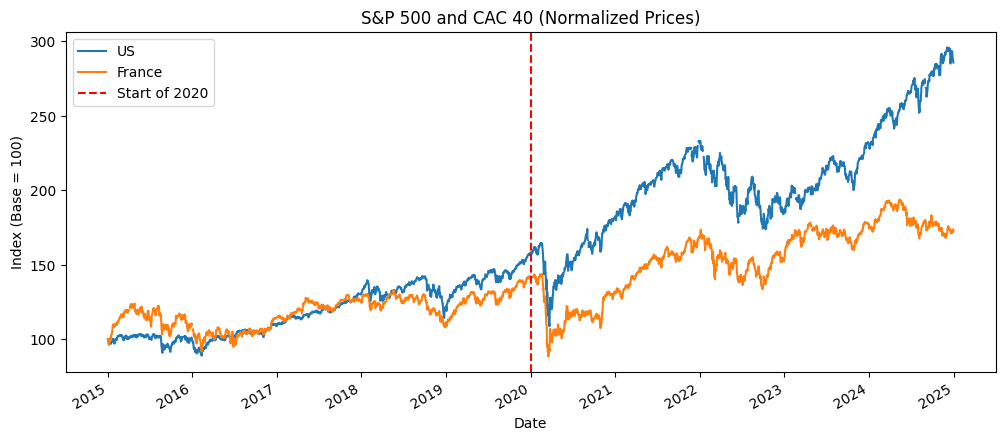

In [11]:
prices.loc["2015":"2024"].div(
    prices.loc["2015":"2024"].iloc[0]
).mul(100).plot(figsize=(12, 5))

plt.axvline(
    pd.Timestamp("2020-01-01"),
    linestyle="--",
    color="red",
    label="Start of 2020"
)

plt.title("S&P 500 and CAC 40 (Normalized Prices)")
plt.ylabel("Index (Base = 100)")
plt.xlabel("Date")
plt.legend()
plt.show()

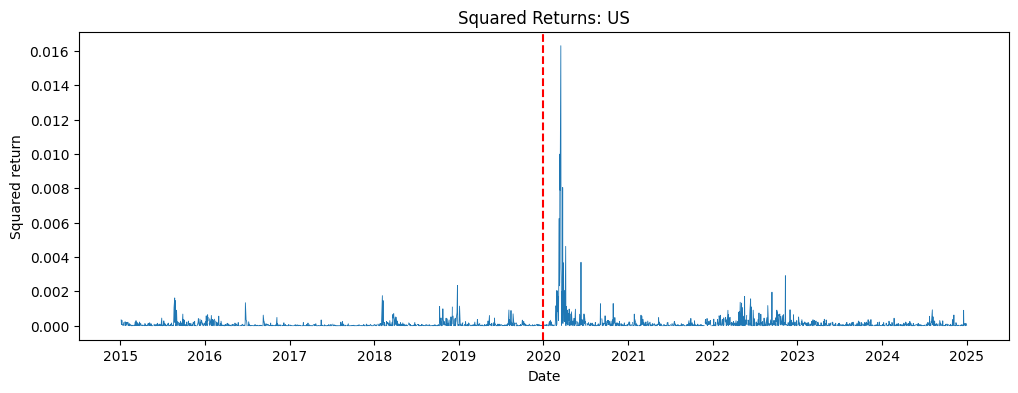

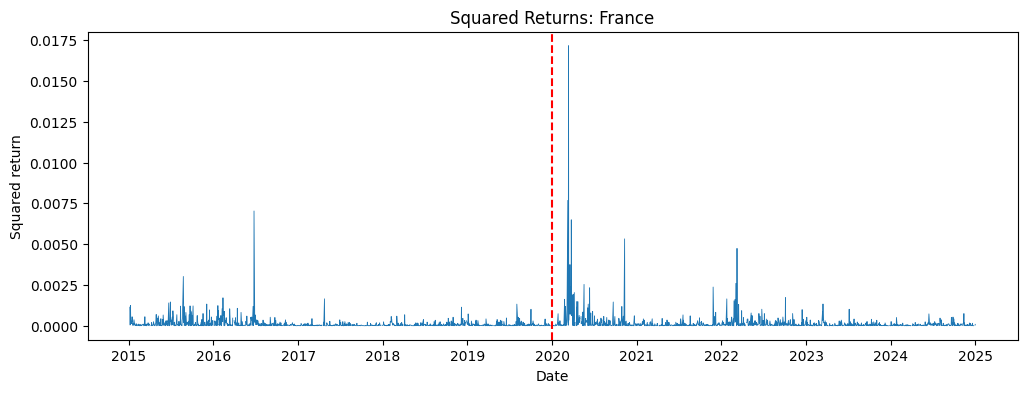

In [ ]:
for country in ["US", "France"]:
    plt.figure(figsize=(12, 4))
    plt.plot(R.index, R[country] ** 2, linewidth=0.6)# test nhap de git len 

    plt.axvline(
        pd.Timestamp("2020-01-01"),
        linestyle="--",
        color="red"
    )

    plt.title(f"Squared Returns: {country}")
    plt.xlabel("Date")
    plt.ylabel("Squared return")
    plt.show()